# Google Cluster Trace 2011 — Exploratory Data Analysis

This notebook inspects one representative shard from each of the official job-event and task-event tables. It loads only these downloaded shards and uses the official `schema.csv` to assign confirmed column names.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# Use the project location directly so execution works from both notebook and repository directories.
ROOT = Path('/home/Ironman/cloud-failure-prediction')

SCHEMA_PATH = ROOT / "ml/dataset/sample/schema.csv"
JOB_PATH = ROOT / "ml/dataset/raw/job_events/part-00000-of-00500.csv.gz"
TASK_PATH = ROOT / "ml/dataset/raw/task_events/part-00000-of-00500.csv.gz"
PLOT_DIR = ROOT / "ml/results/plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {ROOT}")

Project root: /home/Ironman/cloud-failure-prediction


## 1. Schema and data loading

The source files have no header row. Column names are selected from the official schema by matching the file pattern and field number.

In [2]:
schema = pd.read_csv(SCHEMA_PATH)

def get_confirmed_columns(file_pattern):
    prefix = file_pattern.split('/')[0]
    rows = schema[schema['file pattern'].str.startswith(prefix, na=False)].copy()
    rows = rows.sort_values('field number')
    return rows['content'].tolist()

job_columns = get_confirmed_columns('job_events')
task_columns = get_confirmed_columns('task_events')
print('Job columns:', job_columns)
print('Task columns:', task_columns)

Job columns: ['time', 'missing info', 'job ID', 'event type', 'user', 'scheduling class', 'job name', 'logical job name']
Task columns: ['time', 'missing info', 'job ID', 'task index', 'machine ID', 'event type', 'user', 'scheduling class', 'priority', 'CPU request', 'memory request', 'disk space request', 'different machines restriction']


In [3]:
jobs = pd.read_csv(JOB_PATH, compression='gzip', header=None, names=job_columns, low_memory=True)
tasks = pd.read_csv(TASK_PATH, compression='gzip', header=None, names=task_columns, low_memory=True)

print('Job shape:', jobs.shape)
print('Task shape:', tasks.shape)

Job shape: (10704, 8)
Task shape: (450146, 13)


## 2. Basic inspection

This section reports shapes, actual column types, and the first records without modifying the source data.

In [4]:
print('JOB TABLE')
display(jobs.dtypes.to_frame('dtype'))
display(jobs.head())

print('TASK TABLE')
display(tasks.dtypes.to_frame('dtype'))
display(tasks.head())

JOB TABLE


,dtype
time,int64
missing info,float64
job ID,int64
event type,int64
user,str
scheduling class,int64
job name,str
logical job name,str


,time,missing info,job ID,event type,user,scheduling class,job name,logical job name
0,0,NaN,3418309,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,IHgtoxEBuUTHNbUeVs4hzptMY4n8rZKLbZg+Jh5fNG4=,wAmgn2H74cdoMuSFwJF3NaUEaudVBTZ0/HaNZBwIpEQ=
1,0,NaN,3418314,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,L52XDyhi9x9ChmVBZ1qavOFmnzPeVsvQ2QyGmBZcV4s=,ShNjeaoUeqGV2i9WMKEX9HTeuc9K2Fdfovibt7Mp6qI=
2,0,NaN,3418319,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,vq0IN3BWEbkDjYgYvkrVyH6OWoUoDwFFf3j/syEZzLA=,1A2GM17AzHRcKJcJet/oIF7FOORyFcAOcUSpR9Fqou8=
3,0,NaN,3418324,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,X+Vce15Yu3BCKb7Ttc6hvINAzdfG3NtYEDNNsPdMGKo=,seczVo7MBfi/kH3+eH/40Hxs0l2YKFtXFnamcvMjSQI=
4,0,NaN,3418329,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,EeK3DUWYi1P0vgBTp7wZdUos8UKj/+/FqudTLohMQ9M=,OEeQsaVr4kdGHFwQ2liQlDZ18529HEMmu6B6/3K1cBA=


TASK TABLE


,dtype
time,int64
missing info,float64
job ID,int64
task index,int64
machine ID,float64
event type,int64
user,str
scheduling class,int64
priority,int64
CPU request,float64


,time,missing info,job ID,task index,machine ID,event type,user,scheduling class,priority,CPU request,memory request,disk space request,different machines restriction
0,0,2.0,3418309,0,4.155527e+09,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,NaN,NaN,NaN,NaN
1,0,2.0,3418309,1,3.291507e+08,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,NaN,NaN,NaN,NaN
2,0,NaN,3418314,0,3.938719e+09,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,0.125,0.07446,0.000424,0.0
3,0,NaN,3418314,1,3.516186e+08,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,0.125,0.07446,0.000424,0.0
4,0,2.0,3418319,0,4.310529e+08,0,70s3v5qRyCO/1PCdI6fVXnrW8FU/w+5CKRSa72xgcIo=,3,9,NaN,NaN,NaN,NaN


## 3. Missing values and duplicates

Blank fields remain as missing values. No rows or columns are silently dropped.

In [5]:
def data_quality_report(df, table_name):
    report = pd.DataFrame({
        'missing_count': df.isna().sum(),
        'missing_percent': df.isna().mean().mul(100).round(3)
    })
    report['duplicate_records'] = df.duplicated().sum()
    print(f'{table_name}: {len(df):,} rows; {df.duplicated().sum():,} duplicate records')
    display(report)
    return report

job_missing = data_quality_report(jobs, 'Job events')
task_missing = data_quality_report(tasks, 'Task events')

Job events: 10,704 rows; 0 duplicate records


,missing_count,missing_percent,duplicate_records
time,0,0.0,0
missing info,10704,100.0,0
job ID,0,0.0,0
event type,0,0.0,0
user,0,0.0,0
scheduling class,0,0.0,0
job name,0,0.0,0
logical job name,0,0.0,0


Task events: 450,146 rows; 0 duplicate records


,missing_count,missing_percent,duplicate_records
time,0,0.000,0
missing info,449855,99.935,0
job ID,0,0.000,0
task index,0,0.000,0
machine ID,119565,26.561,0
event type,0,0.000,0
user,0,0.000,0
scheduling class,0,0.000,0
priority,0,0.000,0
CPU request,291,0.065,0


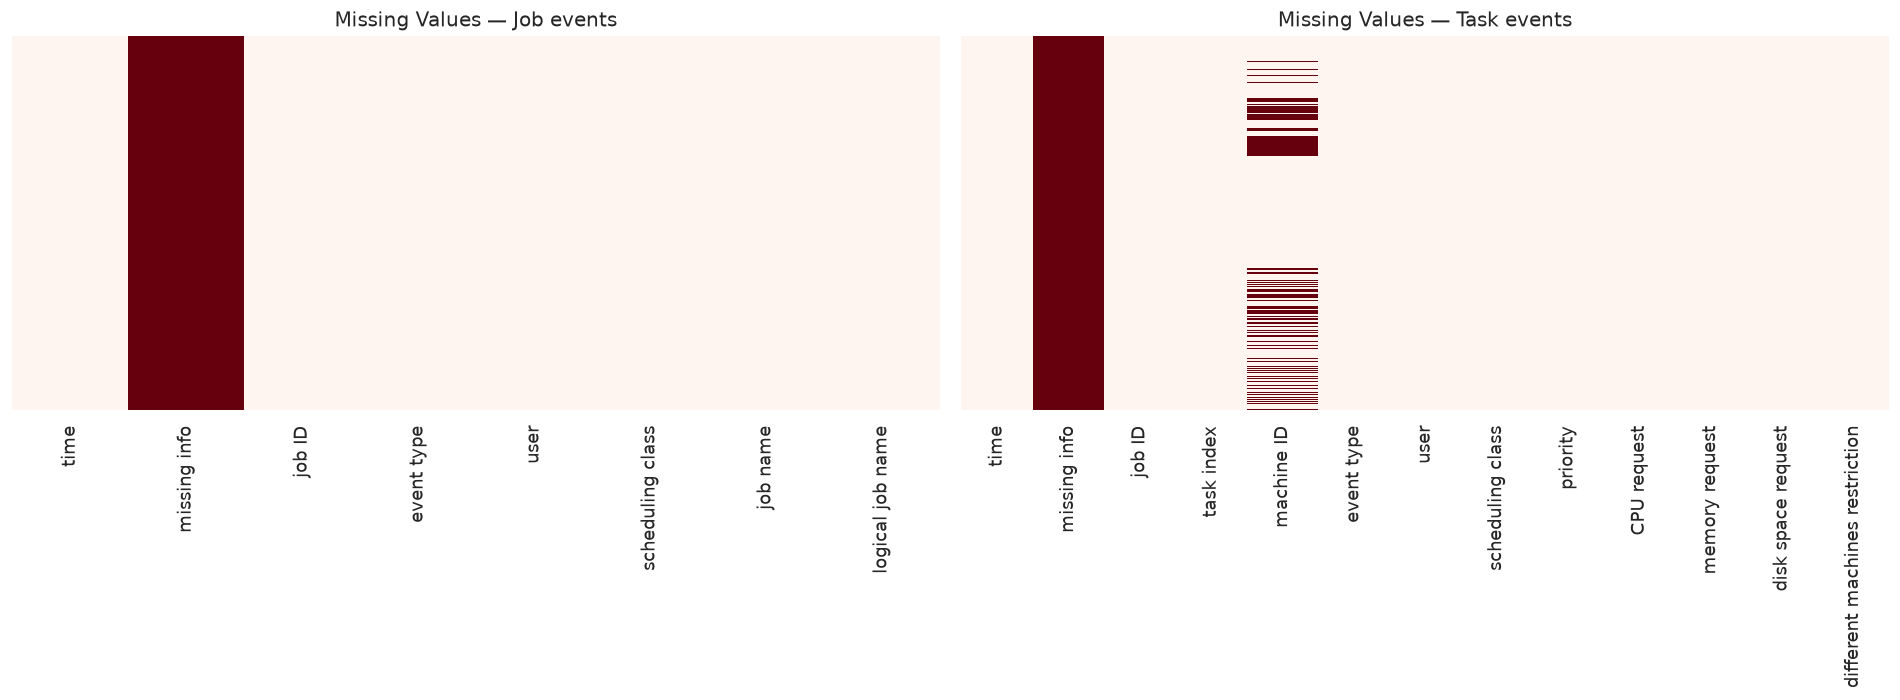

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, df, title in zip(axes, [jobs, tasks], ['Job events', 'Task events']):
    sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap='Reds', ax=ax)
    ax.set_title(f'Missing Values — {title}')
plt.tight_layout()
missing_path = PLOT_DIR / 'missing_values_heatmap.png'
plt.savefig(missing_path, bbox_inches='tight')
plt.show()

## 4. Unique identifiers

A job ID identifies a job. In the task table, the `(job ID, task index)` pair identifies an individual task.

In [7]:
print('Unique job IDs in job events:', jobs['job ID'].nunique())
print('Unique job IDs in task events:', tasks['job ID'].nunique())
task_keys = tasks[['job ID', 'task index']].drop_duplicates()
print('Unique (job ID, task index) tasks:', len(task_keys))

Unique job IDs in job events: 4900
Unique job IDs in task events: 4895


Unique (job ID, task index) tasks: 190926


## 5. Event type distributions

Event type values are numeric codes. Counts below show their observed frequency in the downloaded representative shards.

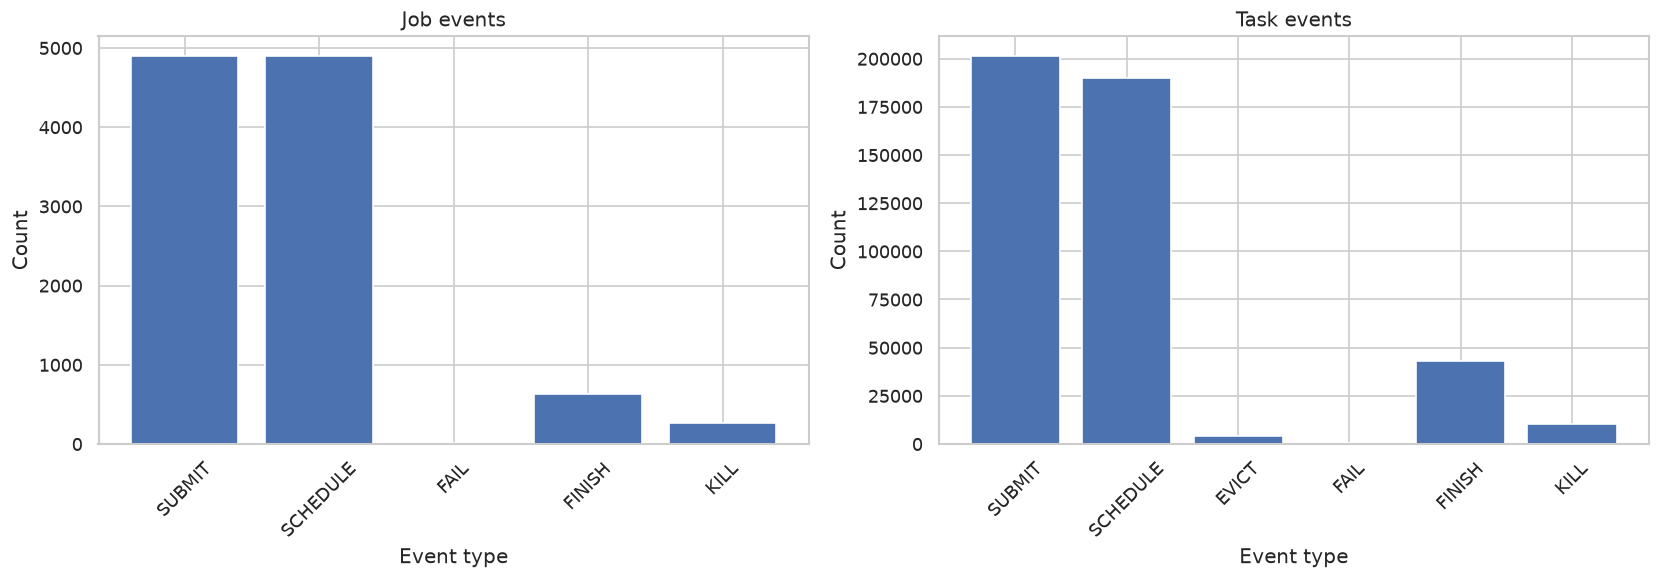

In [8]:
event_labels = {0: 'SUBMIT', 1: 'SCHEDULE', 2: 'EVICT', 3: 'FAIL', 4: 'FINISH', 5: 'KILL', 6: 'LOST', 7: 'UPDATE_PENDING', 8: 'UPDATE_RUNNING'}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, df, title in zip(axes, [jobs, tasks], ['Job events', 'Task events']):
    counts = df['event type'].value_counts().sort_index()
    labels = [event_labels.get(code, str(code)) for code in counts.index]
    ax.bar(labels, counts.values)
    ax.set_title(title)
    ax.set_xlabel('Event type')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
event_path = PLOT_DIR / 'event_type_distribution.png'
plt.savefig(event_path, bbox_inches='tight')
plt.show()

## 6. Scheduling class and task priority distributions

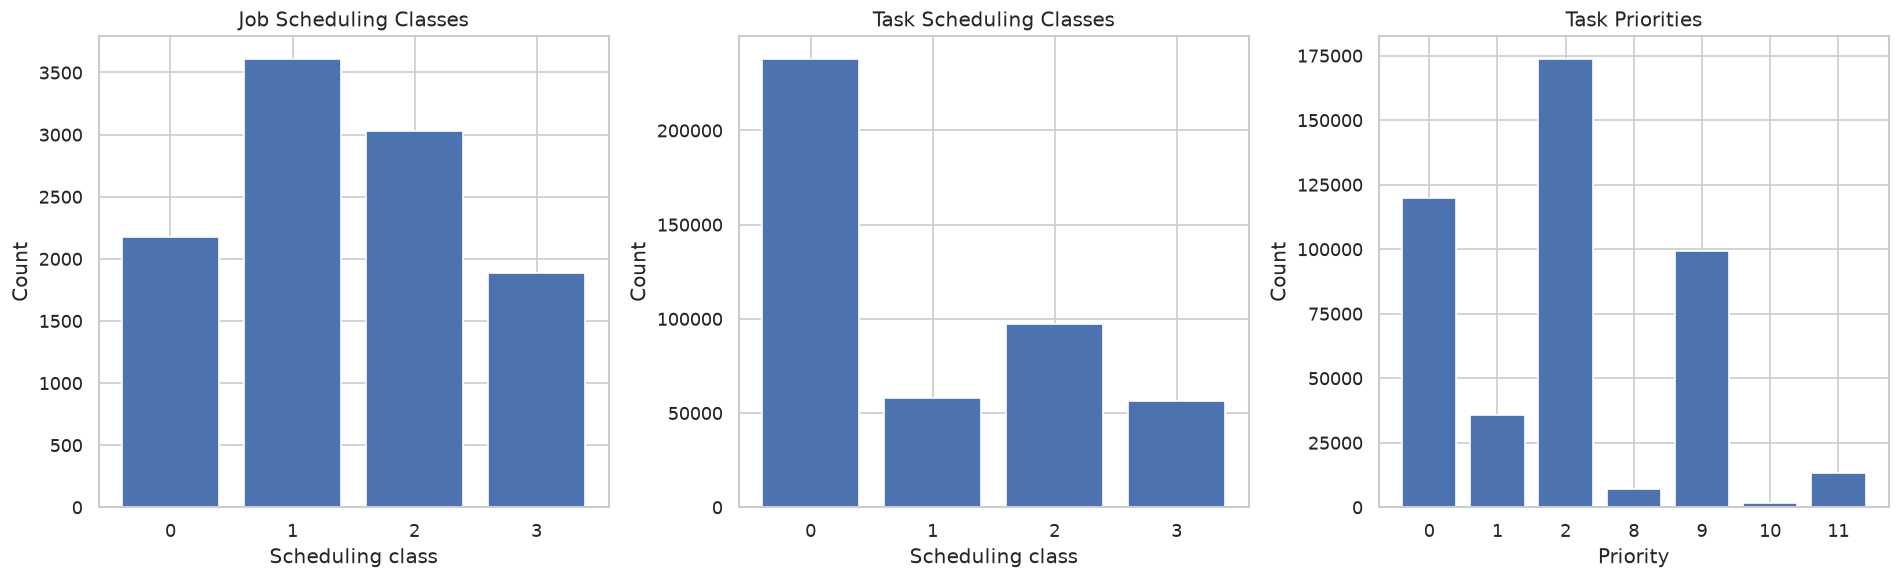

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
job_counts = jobs['scheduling class'].dropna().value_counts().sort_index()
axes[0].bar(job_counts.index.astype(str), job_counts.values)
axes[0].set_title('Job Scheduling Classes')
axes[0].set_xlabel('Scheduling class')
axes[0].set_ylabel('Count')

task_counts = tasks['scheduling class'].dropna().value_counts().sort_index()
axes[1].bar(task_counts.index.astype(str), task_counts.values)
axes[1].set_title('Task Scheduling Classes')
axes[1].set_xlabel('Scheduling class')
axes[1].set_ylabel('Count')

priority_counts = tasks['priority'].value_counts().sort_index()
axes[2].bar(priority_counts.index.astype(str), priority_counts.values)
axes[2].set_title('Task Priorities')
axes[2].set_xlabel('Priority')
axes[2].set_ylabel('Count')

plt.tight_layout()
class_priority_path = PLOT_DIR / 'scheduling_class_priority_distribution.png'
plt.savefig(class_priority_path, bbox_inches='tight')
plt.show()

## 7. Resource request distributions

Only task request fields are visualized. Requested values are retained unchanged; the plot uses clipping for presentation only.

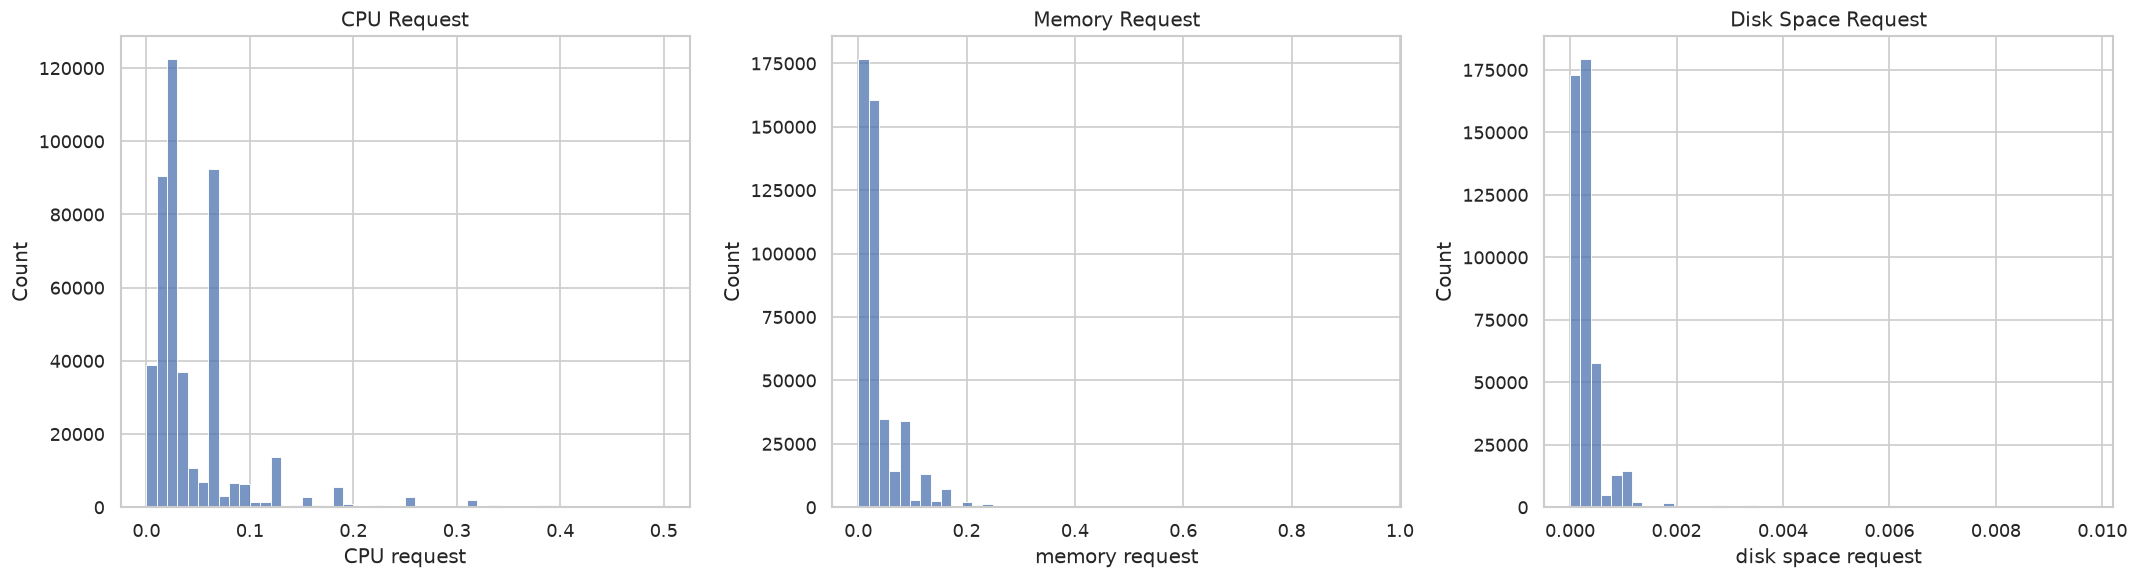

In [10]:
resource_columns = ['CPU request', 'memory request', 'disk space request']
resource_titles = ['CPU Request', 'Memory Request', 'Disk Space Request']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column, title in zip(axes, resource_columns, resource_titles):
    values = tasks[column].dropna()
    if not values.empty:
        sns.histplot(values, bins=50, ax=ax)
        ax.set_title(title)
        ax.set_xlabel(column)
        ax.set_ylabel('Count')
plt.tight_layout()
resource_path = PLOT_DIR / 'task_resource_distribution.png'
plt.savefig(resource_path, bbox_inches='tight')
plt.show()

## 8. Numeric correlations

Correlations include only numeric columns and pairs with sufficient observed values. The task-table heatmap is best for resource relationships.

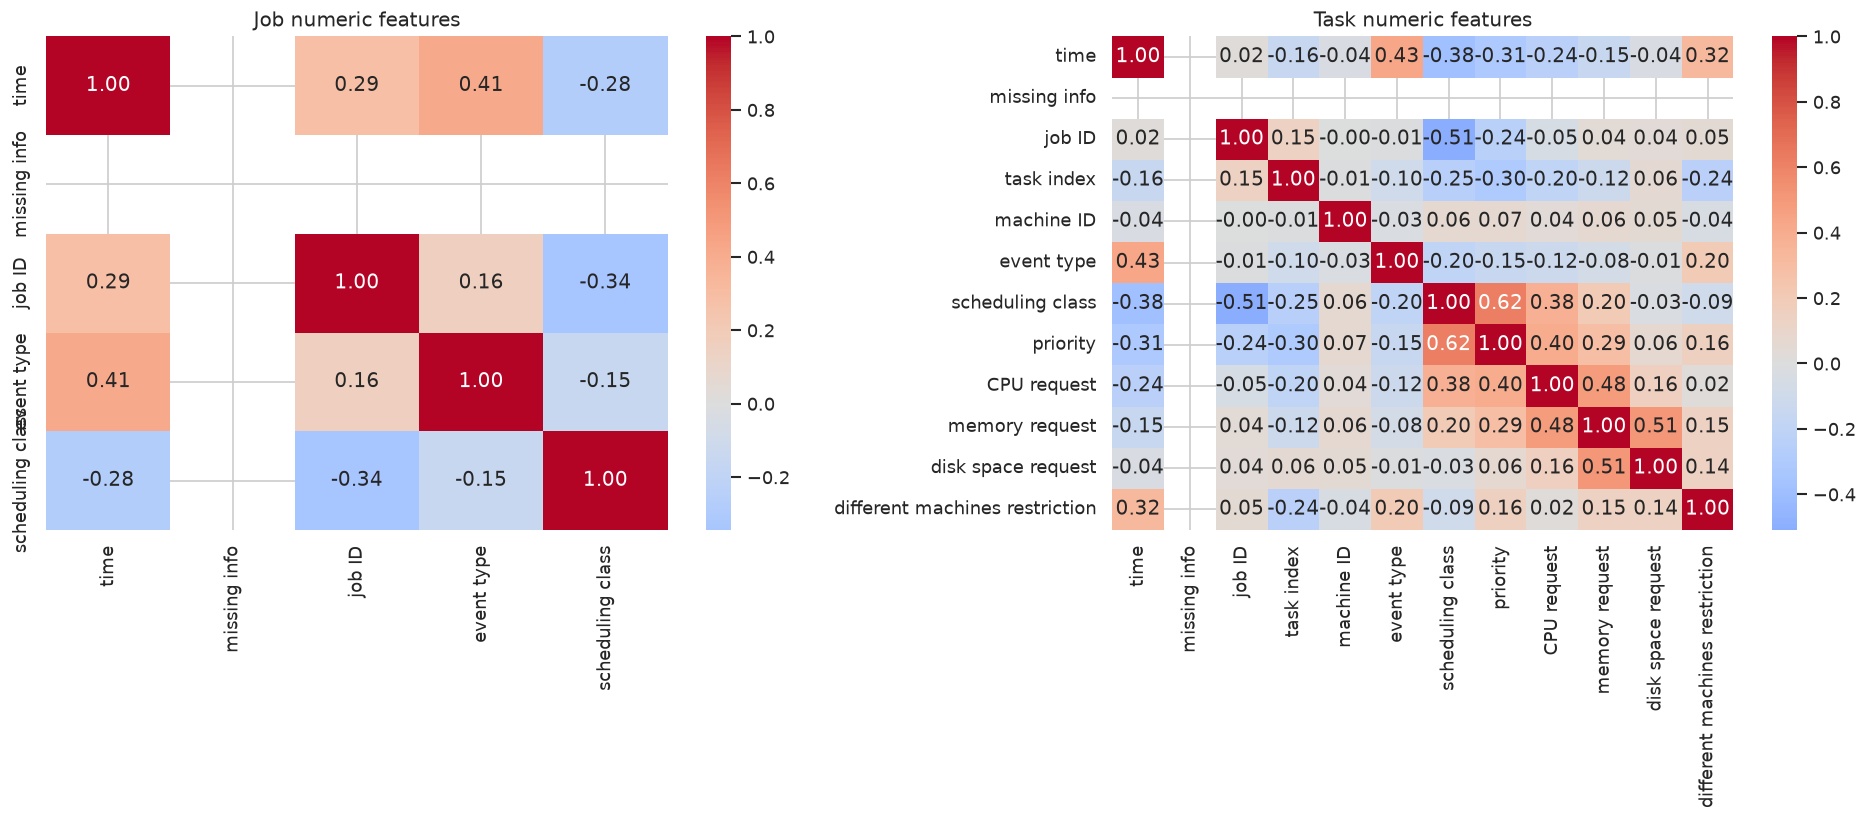

In [11]:
numeric_jobs = jobs.select_dtypes(include=np.number)
numeric_tasks = tasks.select_dtypes(include=np.number)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, df, title in zip(axes, [numeric_jobs, numeric_tasks], ['Job numeric features', 'Task numeric features']):
    corr = df.corr(min_periods=30)
    if corr.shape[0] > 1:
        sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
    ax.set_title(title)
plt.tight_layout()
correlation_path = PLOT_DIR / 'numeric_correlation_heatmap.png'
plt.savefig(correlation_path, bbox_inches='tight')
plt.show()

## 9. EDA findings summary

In [12]:
findings = {
    'job_rows': len(jobs),
    'job_columns': len(jobs.columns),
    'task_rows': len(tasks),
    'task_columns': len(tasks.columns),
    'unique_jobs_job_table': jobs['job ID'].nunique(),
    'unique_jobs_task_table': tasks['job ID'].nunique(),
    'unique_task_keys': len(task_keys),
    'job_duplicate_rows': int(jobs.duplicated().sum()),
    'task_duplicate_rows': int(tasks.duplicated().sum()),
    'job_event_counts': jobs['event type'].value_counts().sort_index().to_dict(),
    'task_event_counts': tasks['event type'].value_counts().sort_index().to_dict(),
}
print('EDA findings')
for key, value in findings.items():
    print(f'{key}: {value}')

EDA findings
job_rows: 10704
job_columns: 8
task_rows: 450146
task_columns: 13
unique_jobs_job_table: 4900
unique_jobs_task_table: 4895
unique_task_keys: 190926
job_duplicate_rows: 0
task_duplicate_rows: 0
job_event_counts: {0: 4900, 1: 4892, 3: 8, 4: 636, 5: 268}
task_event_counts: {0: 201491, 1: 189994, 2: 4338, 3: 581, 4: 43237, 5: 10505}
